<a href="https://colab.research.google.com/github/shengpu-tang/RL-Off-by-a-Beat/blob/main/Toy_Problem_Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['font.family'] = 'STIXGeneral'
%config InlineBackend.figure_formats = ['svg']
from scipy.integrate import solve_ivp

## Continuous-Time Control Task

$\operatorname{sign}(y'(t)) = u(t)$

$y'(t) = \frac{1}{\tau}(u(t)-y(t))$

In [2]:
import numpy as np
from dataclasses import dataclass
from typing import Callable, Tuple, Dict, Any, Optional

@dataclass
class BinaryExp1D:
    """
    1D continuous state x in [0,1] with binary control u in {0,1}.
    Dynamics:
      if u=1: dx/dt = (1-x) / τ_1     -> increase, x(t+δ) = 1 - (1-x)*exp(-δ/τ_1)
      if u=0: dx/dt = (0-x) / τ_0     -> decrease, x(t+δ) = x*exp(-δ/τ_0)
    """
    dt: float = 1.0             # time elapsed per step()
    x: float = 0.0              # current state
    x_min: float = 0.0          # minimum state
    x_max: float = 1.0          # maximum state
    tau_1: float = 1.0          # rate of expoential increase when u=1
    tau_0: float = 1.0          # rate of expoential decrease when u=0
    clip_state: bool = True     # keep x in [x_min, x_max]

    def reset(self, x0: Optional[float] = None) -> float:
        if x0 is not None:
            self.x = float(x0)
        else:
            self.x = float(np.random.random())
        return self.x

    def _internal_step(self, x: float, u: int, δ: float) -> float:
        if u == 1:
            return 1.0 - (1.0 - x) * np.exp(-δ / self.tau_1)
        else:
            return x * np.exp(-δ / self.tau_0)

    def step(self, u: int, internal_dt: Optional[float] = None):
        """
        Evolves system for self.dt by numerical integration at internal_dt resolution.
        """
        step_dt = self.dt
        if internal_dt is None:
            internal_dt = step_dt # Use self.dt as default when internal_dt is None

        if internal_dt > step_dt:
            raise ValueError("internal_dt must be smaller than step_dt")
        else:
            n_sub = int(np.ceil(step_dt / internal_dt))
            internal_dt = step_dt / n_sub  # adjust to fit evenly

        x_traj = [self.x]
        t_traj = [0.0]

        x_curr = self.x
        for i in range(n_sub):
            x_next = self._internal_step(x_curr, u, internal_dt)
            if self.clip_state:
                x_next = float(np.clip(x_next, self.x_min, self.x_max))

            x_curr = x_next
            t_traj.append((i + 1) * internal_dt)
            x_traj.append(x_curr)

        # Reward is indicator of whether x has increased
        reward = float(int(x_curr >= self.x))
        self.x = x_curr

        done = False

        info = {"u": u}
        if internal_dt is not None:
            info["internal_t"] = np.array(t_traj)
            info["internal_x"] = np.array(x_traj)
            info["internal_u"] = np.array([u] * len(t_traj))

        return float(self.x), reward, done, info

### Helper functions

- rollout_policy()
- HysteresisPolicy
- stitch_internal_traj()

In [3]:
def rollout_policy(
    env: BinaryExp1D,
    policy: Callable[[float, float], Any],
    T: float,
    x0: Optional[float] = None,
) -> Dict[str, np.ndarray]:
    """
    Evaluate an arbitrary policy pi(t, x) at discrete times t_k with ZOH over each step.
    - policy: function taking (t, x) and returning a control (we threshold to {0,1}).
    - T: total simulation horizon (seconds).
    - dt: override env.dt if provided (env is stepped with that dt).
    Returns dict with arrays: t, x, u, r
    """
    t = 0.0
    n_steps = int(np.ceil(T / env.dt))

    x_hist, u_hist, r_hist, t_hist, info_list = [], [], [], [], []

    x = env.reset(x0 if x0 is not None else env.x)

    for k in range(n_steps):
        u = policy(t, x)
        x, r, done, info = env.step(u, internal_dt=0.01)
        x_hist.append(x)
        u_hist.append(int(float(u) >= 0.5))
        r_hist.append(r)
        t_hist.append(t + env.dt)
        info_list.append(info)
        t += env.dt
        if done:
            break

    return {
        "t": np.array(t_hist, dtype=float),
        "x": np.array(x_hist, dtype=float),
        "u": np.array(u_hist, dtype=int),
        "r": np.array(r_hist, dtype=float),
        "info": info_list,
    }

In [4]:
# a simple hysteresis policy (avoids chatter):
# turn ON if x < 0.4; turn OFF if x > 0.6; otherwise keep previous action
class HysteresisPolicy:
    def __init__(self, low=0.1, high=0.9, u0=1):
        self.low = low
        self.high = high
        self.u = u0
    def __call__(self, t, x):
        if x < self.low:
            self.u = 1
        elif x > self.high:
            self.u = 0
        return self.u

In [5]:
def stitch_internal_traj(info_list, step_dt):
    t_traj = []
    x_traj = []
    u_traj = []

    t0 = 0.0
    step = 0
    for info in info_list:
        it = np.asarray(info["internal_t"])
        ix = np.asarray(info["internal_x"])
        iu = np.asarray(info["internal_u"])
        u = int(info["u"])
        t_abs = t0 + it  # shift internal times to absolute
        if step < len(info_list) - 1:
            t_traj.append(t_abs[:-1])
            x_traj.append(ix[:-1])
            u_traj.append(iu[:-1])
            # u_traj.extend([u] * (len(t_abs)-1))
        else:
            t_traj.append(t_abs)
            x_traj.append(ix)
            u_traj.append(iu)
            # u_traj.extend([u] * len(t_abs))

        t0 += step_dt
        step += 1

    t_traj_ = [t_traj__[0] for t_traj__ in t_traj]
    u_traj_ = [info['u'] for info in info_list]

    t_traj = np.concatenate(t_traj)
    x_traj = np.concatenate(x_traj)
    u_traj = np.concatenate(u_traj)
    u_traj = np.array(u_traj, dtype=int)

    return t_traj, x_traj, u_traj, t_traj_, u_traj_

### Plotting

In [6]:
env = BinaryExp1D(tau_1=0.3, tau_0=0.3, dt=1.0)
pi = HysteresisPolicy(low=0.1, high=0.9, u0=1)
out = rollout_policy(env, pi, T=4.0, x0=0.1)

# quick check
print("Final state:", out["x"][-1])
print("Average control usage:", out["u"].mean())

t_traj, x_traj, u_traj, t_traj_, u_traj_ = stitch_internal_traj(out["info"], step_dt=env.dt)

Final state: 0.03444530183856196
Average control usage: 0.5


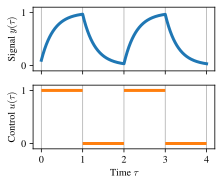

In [7]:
# Plotting
fig, axes = plt.subplots(2, 1, figsize=(3,2.5), sharex=True)
c1 = 'tab:blue'
c2 = 'tab:orange'
axes[0].grid(axis='x')
axes[1].grid(axis='x')
axes[0].plot(t_traj, x_traj, lw=3, color=c1)
# axes[1].plot(t_traj, u_traj, lw=3, color=c2)
axes[1].hlines(u_traj_, t_traj_, t_traj_[1:] + [t_traj[-1]], lw=3, color=c2)
# axes[1].plot(t_traj_, u_traj_, lw=0, marker='s', color=c2)
axes[0].set_ylim(-0.1, 1.1)
axes[1].set_ylim(-0.1, 1.1)
axes[0].set_yticks([0, 1.0])
axes[1].set_yticks([0, 1.0])
plt.tight_layout()
plt.savefig('toy_problem_NEW.pdf', bbox_inches='tight')
plt.xlabel('Time $\\tau$')
axes[0].set_ylabel('Signal $y(\\tau)$')
axes[1].set_ylabel('Control $u(\\tau)$')
plt.savefig('toy_problem_NEW_labeled.pdf', bbox_inches='tight')
plt.show()

## Simulation Experiments

In [10]:
import numpy as np
from tqdm import tqdm

import gymnasium as gym
from gymnasium.envs.toy_text.utils import categorical_sample
from gymnasium.wrappers import TimeLimit

from collections import defaultdict
from typing import List, Optional

In [11]:
nS, nA = 2, 2

class ToyEnvNew(gym.Env):
    """
    A wrapper around the continuous BinaryExp1D system with
    discrete-state (2 states: decreasing or increasing/steady) and
    discrete-action (2 actions: off and on).
    With slip_prob chance the requested action is ineffective and
    the previously applied control persists.
    """

    def __init__(self, **kwargs):
        super().__init__()

        self.slip_prob = kwargs.pop('slip_prob', 0.0)
        self.internal_dt = kwargs.pop('internal_dt', None)
        self.continuous_env = BinaryExp1D(**kwargs)

        self.nS = nS
        self.nA = nA
        self.observation_space = gym.spaces.Discrete(self.nS)  # 0: x decreasing, 1: x increasing/steady
        self.action_space = gym.spaces.Discrete(self.nA)       # 0: u=0 (Off), 1: u=1 (On)
        self.isd = np.ones(nS) / nS   # uniform initial state distribution

        # State variables
        self.s = None                  # signal increasing or decreasing
        self.a_last_requested = None   # action requested by agent in the last step
        self.u_last_effective = None   # control input that was actually applied to the system last step - this is contemperaneous with s

        print(f"ToyEnvNew initialized. step_dt={self.continuous_env.dt}, internal_dt={self.internal_dt}, slip_prob={self.slip_prob}")

    def _get_discrete_state(self, x_start: float, x_end: float) -> int:
        """
        Maps continuous state change (x_start -> x_end) to discrete state s in {0, 1}.
        0: x is decreasing (x_end < x_end)
        1: x is increasing (x_end > x_end) or steady
        """
        return 1 if x_end >= x_start else 0

    def step(self, a: int) -> Tuple[int, float, bool, bool, Dict]:
        """
        Execute action on the continuous system at internal_dt reslution.
        Returns the new state (based on direction of change) and internal trajectory of t and x.
        """
        if not self.action_space.contains(a):
            raise ValueError(f"Invalid action: {a}. Must be in {self.action_space}")

        x_start = self.continuous_env.x
        a_requested = a
        slipped = self.np_random.random() < self.slip_prob

        # Determine the action that actually influences the system (u_applied)
        # Use the last effective control if slipped, otherwise use the requested action
        u_applied = self.u_last_effective if slipped else a_requested

        x_end, _, done, info = self.continuous_env.step(int(u_applied), internal_dt=self.internal_dt)
        s_next = self._get_discrete_state(x_start, x_end)

        # Update state variables
        self.s = s_next
        self.a_last_requested = a_requested
        self.u_last_effective = u_applied

        info["continuous_x_start"] = x_start
        info["continuous_x_end"] = x_end
        info["slip_status"] = "slip" if slipped else "success"
        info["a_last_requested"] = a_requested
        info["u_last_effective"] = u_applied

        # truncation=False, will be handled by the `TimeLimit` wrapper added during `make`
        return s_next, float(s_next), done, False, info

    def reset(self, seed: Optional[int] = None, options: Optional[Dict] = None) -> Tuple[int, Dict]:
        super().reset(seed=seed)

        if options and "s" in options:
            self.s = options["s"]
        else:
            self.s = int(categorical_sample(self.isd, self.np_random))

        # Reset continuous env (x0 will be random unless specified in options)
        x0 = options.get("x0") if options and "x0" in options else None
        self.continuous_env.reset(x0=x0)

        self.a_last_requested = self.s    # assume last requested action is consistent with current state
        self.u_last_effective = self.s    # assume last applied action is consistent with current state

        info = {"continuous_x0": self.continuous_env.x}

        return self.s, info


### Model-based RL functions

In [12]:
def calculate_discounted_return(episode: List[Tuple[int, int, int, float, int]], gamma: float = 0.9) -> float:
    """
    Calculates the discounted return (G_0) for a single episode.
    G_t = R_{t+1} + gamma * R_{t+2} + gamma^2 * R_{t+3} + ...
    episode: list of (a_curr, s, a, r, s_next) tuples
    """
    rewards = [step[3] for step in episode]
    discounted_return = 0.0
    for t, reward in enumerate(rewards):
        discounted_return += (gamma ** t) * reward
    return discounted_return

In [13]:
def calculate_reward_function(episodes):
    R_samples = defaultdict(list)
    for ep in episodes:
        for S, A, R, S_next in ep:
            R_samples[S, A].append(R)

    R = np.zeros((nS, nA))
    for s in range(nS):
        for a in range(nA):
            R[s,a] = np.mean(R_samples[s,a])

    return R

def calculate_transition_function(episodes):
    P = np.zeros((nS, nA, nS))
    for ep in episodes:
        for S, A, R, S_next in ep:
            P[S, A, S_next] += 1

    for s in range(nS):
        for a in range(nA):
            P[s, a, :] /= np.sum(P[s, a, :])

    return P

def value_iteration(P, R, gamma=0.9, theta=1e-10):
    # VI algorithm
    V = np.zeros(nS)
    while True:
        Q = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                Q[s,a] = R[s,a] + gamma * np.nansum(P[s,a,:] * V)

        V_new = np.nanmax(Q, axis=1)
        delta = np.nanmax(np.abs(V_new - V))
        V = V_new
        if delta < theta:
            break

    # Calculate final Q-values
    Q = np.zeros((nS, nA))
    for s in range(nS):
        for a in range(nA):
            Q[s,a] = R[s,a] + gamma * np.nansum(P[s,a,:] * V)

    # Final policy with tie-breaking
    π = (Q == np.nanmax(Q, axis=1, keepdims=True))
    π = π / π.sum(axis=1, keepdims=True)

    return V, Q, π

def policy_evaluation_iterative(P, R, π, gamma=0.9, theta=1e-10):
    V = np.zeros(nS)
    while True:
        Q = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                Q[s,a] = R[s,a] + gamma * np.nansum(P[s,a,:] * V)

        V_new = np.nansum(π * Q, axis=1)
        delta = np.nanmax(np.abs(V_new - V))
        V = V_new
        if delta < theta:
            break

    # Calculate final Q-values
    Q = np.zeros((nS, nA))
    for s in range(nS):
        for a in range(nA):
            Q[s,a] = R[s,a] + gamma * np.nansum(P[s,a,:] * V)

    return V, Q

def policy_evaluation(envP, π, gamma=0.9, theta=1e-10):
    V = np.zeros(nS)
    while True:
        delta = 0
        for s in range(nS):
            v = 0
            for a, a_prob in enumerate(π[s]):
                for prob, next_state, reward, done in envP[s][a]:
                    v += a_prob * prob * (reward + (1 - done) * gamma * V[next_state])

            delta = max(delta, np.abs(v - V[s]))
            V[s] = v
        if delta < theta:
            break
    return V

### One Run - debug version

In [14]:
env = TimeLimit(ToyEnvNew(slip_prob=0.2, internal_dt=0.01), max_episode_steps=100)

rng = np.random.default_rng(seed=0)
s, info = env.reset(seed=42)

episode_steps = []
for i in range(10):
    a_curr = int(env.env.a_last_requested)   # a_curr and s are contemporaneous
    a = int(categorical_sample(np.ones(nA)/nA, rng))
    s_next, r, terminated, truncated, info = env.step(a)
    episode_steps.append((a_curr, s, a, r, s_next))
    s = s_next
    if terminated or truncated:
        observation, info = env.reset()
        # print("Environment reset")

ToyEnvNew initialized. step_dt=1.0, internal_dt=0.01, slip_prob=0.2


In [15]:
episode_steps

[(1, 1, 1, 1.0, 1),
 (1, 1, 0, 0.0, 0),
 (0, 0, 0, 0.0, 0),
 (0, 0, 0, 0.0, 0),
 (0, 0, 1, 1.0, 1),
 (1, 1, 1, 1.0, 1),
 (1, 1, 1, 1.0, 1),
 (1, 1, 1, 1.0, 1),
 (1, 1, 1, 1.0, 1),
 (1, 1, 1, 1.0, 1)]

In [16]:
# behavior policy
# prefer the action that would change the state
π_b = np.array([[0.1, 0.9], [0.75, 0.25]])

env = TimeLimit(
    ToyEnvNew(slip_prob=0.2, internal_dt=1),
    max_episode_steps=10,
)

num_episodes = 100
episode_data = []
rng = np.random.default_rng(seed=42)

for ep in tqdm(range(num_episodes)):
    s, info = env.reset(seed=ep)
    episode_steps = []

    while True:
        a_curr = int(env.env.a_last_requested)
        a = rng.choice(nA, p=π_b[s])
        s_next, r, terminated, truncated, info = env.step(a)
        episode_steps.append((a_curr, s, a, r, s_next))
        s = s_next

        if terminated or truncated:
            break

    episode_data.append(episode_steps)

ToyEnvNew initialized. step_dt=1.0, internal_dt=1, slip_prob=0.2


100%|██████████| 100/100 [00:00<00:00, 1516.99it/s]


In [17]:
episode_data[0]

[(1, 1, 1, 1.0, 1),
 (1, 1, 0, 1.0, 1),
 (0, 1, 1, 1.0, 1),
 (1, 1, 0, 0.0, 0),
 (0, 0, 0, 0.0, 0),
 (0, 0, 1, 1.0, 1),
 (1, 1, 1, 1.0, 1),
 (1, 1, 1, 1.0, 1),
 (1, 1, 0, 0.0, 0),
 (0, 0, 1, 1.0, 1)]

In [18]:
episodes_orig = []
for ep in episode_data:
     episodes_orig.append([(s, a_curr, r, s_next) for a_curr, s, a, r, s_next in ep])

episodes_shifted = []
for ep in episode_data:
     episodes_shifted.append([(s, a, r, s_next) for a_curr, s, a, r, s_next in ep])

In [19]:
episodes_orig[0]

[(1, 1, 1.0, 1),
 (1, 1, 1.0, 1),
 (1, 0, 1.0, 1),
 (1, 1, 0.0, 0),
 (0, 0, 0.0, 0),
 (0, 0, 1.0, 1),
 (1, 1, 1.0, 1),
 (1, 1, 1.0, 1),
 (1, 1, 0.0, 0),
 (0, 0, 1.0, 1)]

In [20]:
episodes_shifted[0]

[(1, 1, 1.0, 1),
 (1, 0, 1.0, 1),
 (1, 1, 1.0, 1),
 (1, 0, 0.0, 0),
 (0, 0, 0.0, 0),
 (0, 1, 1.0, 1),
 (1, 1, 1.0, 1),
 (1, 1, 1.0, 1),
 (1, 0, 0.0, 0),
 (0, 1, 1.0, 1)]

In [21]:
R_orig = calculate_reward_function(episodes_orig)
P_orig = calculate_transition_function(episodes_orig)
V_orig, Q_orig, π_orig = value_iteration(P_orig, R_orig)

In [22]:
R_shifted = calculate_reward_function(episodes_shifted)
P_shifted = calculate_transition_function(episodes_shifted)
V_shifted, Q_shifted, π_shifted = value_iteration(P_shifted, R_shifted)

In [23]:
print(R_orig)
print(P_orig)
print(V_orig)
print(Q_orig)
print(π_orig)
print()
print(R_shifted)
print(P_shifted)
print(V_shifted)
print(Q_shifted)
print(π_shifted)

[[0.73474801 0.725     ]
 [0.32352941 0.39368421]]
[[[0.26525199 0.73474801]
  [0.275      0.725     ]]

 [[0.67647059 0.32352941]
  [0.60631579 0.39368421]]]
[5.62182057 5.36086042]
[[5.62182057 5.61436201]
 [5.30718247 5.36086042]]
[[1. 0.]
 [0. 1.]]

[[0.         0.79196217]
 [0.18932039 1.        ]]
[[[1.         0.        ]
  [0.20803783 0.79196217]]

 [[0.81067961 0.18932039]
  [0.         1.        ]]]
[ 9.74403723 10.        ]
[[ 8.76963351  9.74403723]
 [ 9.00256697 10.        ]]
[[0. 1.]
 [0. 1.]]


### Helper functions

- generate_random_behavior_policy()
- generate_dataset()
- run_experiment()
- run_experiment_evaluation()

In [24]:
def generate_random_behavior_policy(n_states=2, n_actions=2, seed=None):
    policy = np.random.default_rng(seed=seed).random((n_states, n_actions))
    for state in range(n_states):
        policy[state] = policy[state] / np.sum(policy[state])
    return policy

def generate_dataset(env, π_b, num_episodes=1, seed=None, show_progress=True):
    episode_data = []
    rng = np.random.default_rng(seed=seed)

    for ep in tqdm(range(num_episodes), disable=(not show_progress)):
        s, info = env.reset(seed=seed*1000+ep)
        episode_steps = []

        while True:
            a_curr = env.env.a_last_requested
            a = rng.choice(nA, p=π_b[s])
            s_next, r, terminated, truncated, info = env.step(a)
            episode_steps.append((a_curr, s, a, r, s_next, info))
            s = s_next

            if terminated or truncated:
                break

        episode_data.append(episode_steps)
    return episode_data

def run_experiment(episode_data):
    episodes_orig = [
        [(s, a_curr, r, s_next) for a_curr, s, a, r, s_next, info in ep] for ep in episode_data
    ]
    episodes_shifted = [
        [(s, a, r, s_next) for a_curr, s, a, r, s_next, info in ep] for ep in episode_data
    ]

    R_orig = calculate_reward_function(episodes_orig)
    P_orig = calculate_transition_function(episodes_orig)
    V_orig, Q_orig, π_orig = value_iteration(P_orig, R_orig)

    R_shifted = calculate_reward_function(episodes_shifted)
    P_shifted = calculate_transition_function(episodes_shifted)
    V_shifted, Q_shifted, π_shifted = value_iteration(P_shifted, R_shifted)

    return {
        'orig': {
            'R': R_orig, 'P': P_orig, 'V': V_orig, 'Q': Q_orig, 'π': π_orig,
        },
        'shifted': {
            'R': R_shifted, 'P': P_shifted, 'V': V_shifted, 'Q': Q_shifted, 'π': π_shifted,
        }
    }

def run_experiment_evaluation(outputs, episode_data, π_b):
    episodes_orig = [
        [(s, a_curr, r, s_next) for a_curr, s, a, r, s_next, info in ep] for ep in episode_data
    ]
    episodes_shifted = [
        [(s, a, r, s_next) for a_curr, s, a, r, s_next, info in ep] for ep in episode_data
    ]

    π_orig = outputs['orig']['π']
    R_orig = calculate_reward_function(episodes_orig)
    P_orig = calculate_transition_function(episodes_orig)
    V_eval_orig, Q_eval_orig = policy_evaluation_iterative(P_orig, R_orig, π_orig)
    V_πb_orig, Q_πb_orig = policy_evaluation_iterative(P_orig, R_orig, π_b)

    π_shifted = outputs['shifted']['π']
    R_shifted = calculate_reward_function(episodes_shifted)
    P_shifted = calculate_transition_function(episodes_shifted)
    V_eval_shifted, Q_eval_shifted = policy_evaluation_iterative(P_shifted, R_shifted, π_shifted)
    V_πb_shifted, Q_πb_shifted = policy_evaluation_iterative(P_shifted, R_shifted, π_b)

    return {
        'orig': {
            'V': V_eval_orig, 'Q': Q_eval_orig,
            'V_πb': V_πb_orig, 'Q_πb': Q_πb_orig,
        },
        'shifted': {
            'V': V_eval_shifted, 'Q': Q_eval_shifted,
            'V_πb': V_πb_shifted, 'Q_πb': Q_πb_shifted,
        }
    }

### One Run - with helper functions

In [25]:
env = TimeLimit(
    ToyEnvNew(slip_prob=0.1),
    max_episode_steps=100,
)

ToyEnvNew initialized. step_dt=1.0, internal_dt=None, slip_prob=0.1


In [26]:
π_b = np.array([[0.05, 0.95], [0.05, 0.95]])
episode_data = generate_dataset(env, π_b, seed=0, num_episodes=100, show_progress=False)
results = run_experiment(episode_data)

In [27]:
results['orig']['π'], results['shifted']['π']

(array([[1., 0.],
        [0., 1.]]),
 array([[0., 1.],
        [0., 1.]]))

In [28]:
test_episode_data = generate_dataset(env, π_b, seed=100, num_episodes=100, show_progress=False)
test_results = run_experiment_evaluation(results, test_episode_data, π_b)

In [29]:
print(test_results['orig']['V_πb'].mean(), test_results['orig']['V'].mean())
print(test_results['shifted']['V_πb'].mean(), test_results['shifted']['V'].mean())

9.40436258629063 9.46564561971919
9.450923263185327 9.949578101632493


In [30]:
online_rollout_orig = generate_dataset(env, results['orig']['π'], seed=100, num_episodes=100, show_progress=False)
online_rollout_shifted = generate_dataset(env, results['shifted']['π'], seed=100, num_episodes=100, show_progress=False)
returns_orig = [calculate_discounted_return(ep) for ep in online_rollout_orig]
returns_shifted = [calculate_discounted_return(ep) for ep in online_rollout_shifted]

In [31]:
print(np.mean(returns_orig), np.mean(returns_shifted))

4.499880473705005 9.959734386011124


In [32]:
π_b = generate_random_behavior_policy(2, 2, seed=3)
episode_data = generate_dataset(env, π_b, seed=42, show_progress=False)
results = run_experiment(episode_data)

In [33]:
results['orig']['π'], results['shifted']['π']

(array([[0., 1.],
        [1., 0.]]),
 array([[0., 1.],
        [0., 1.]]))

In [34]:
test_episode_data = generate_dataset(env, π_b, seed=100, show_progress=False)
test_results = run_experiment_evaluation(results, test_episode_data, π_b)

In [35]:
test_results['orig']['V'], test_results['shifted']['V']

(array([7.57575757, 7.72727273]), array([ 9.89761092, 10.        ]))

In [36]:
online_rollout_orig = generate_dataset(env, results['orig']['π'], seed=100, num_episodes=100, show_progress=False)
online_rollout_shifted = generate_dataset(env, results['shifted']['π'], seed=100, num_episodes=100, show_progress=False)
returns_orig = [calculate_discounted_return(ep) for ep in online_rollout_orig]
returns_shifted = [calculate_discounted_return(ep) for ep in online_rollout_shifted]

In [37]:
print(np.mean(returns_orig), np.mean(returns_shifted))

5.037388576503491 9.959734386011124


## Main Experiments

### Learning

In [ ]:
MAX_EPISODES_STEPS = 100
NUM_EPISODES = 100

In [ ]:
env = TimeLimit(
    ToyEnvNew(slip_prob=0.2),
    max_episode_steps=MAX_EPISODES_STEPS,
)

ToyEnvNew initialized. step_dt=1.0, internal_dt=None, slip_prob=0.2


In [ ]:
all_results = []
for run in tqdm(range(100)):
    π_b = generate_random_behavior_policy(2, 2, seed=run)
    episode_data = generate_dataset(env, π_b, num_episodes=NUM_EPISODES, seed=100+run, show_progress=False)
    results = run_experiment(episode_data)
    all_results.append(results)

100%|██████████| 100/100 [01:04<00:00,  1.54it/s]


In [ ]:
# average P
avg_P_orig = np.mean([results['orig']['P'] for results in all_results], axis=0)
avg_P_shifted = np.mean([results['shifted']['P'] for results in all_results], axis=0)

In [ ]:
avg_P_orig, avg_P_shifted

(array([[[0.6090147 , 0.3909853 ],
         [0.61380571, 0.38619429]],
 
        [[0.40171002, 0.59828998],
         [0.39838722, 0.60161278]]]),
 array([[[1.        , 0.        ],
         [0.20035621, 0.79964379]],
 
        [[0.80005764, 0.19994236],
         [0.        , 1.        ]]]))

In [ ]:
# average R
avg_R_orig = np.mean([results['orig']['R'] for results in all_results], axis=0)
avg_R_shifted = np.mean([results['shifted']['R'] for results in all_results], axis=0)

In [ ]:
avg_R_orig, avg_R_shifted

(array([[0.3909853 , 0.38619429],
        [0.59828998, 0.60161278]]),
 array([[0.        , 0.79964379],
        [0.19994236, 1.        ]]))

In [ ]:
# average V
avg_V_orig = np.mean([results['orig']['V'] for results in all_results], axis=0)
avg_V_shifted = np.mean([results['shifted']['V'] for results in all_results], axis=0)

# average Q
avg_Q_orig = np.mean([results['orig']['Q'] for results in all_results], axis=0)
avg_Q_shifted = np.mean([results['shifted']['Q'] for results in all_results], axis=0)

In [ ]:
# average π
avg_π_orig = np.mean([results['orig']['π'] for results in all_results], axis=0)
avg_π_shifted = np.mean([results['shifted']['π'] for results in all_results], axis=0)

In [ ]:
avg_π_orig, avg_π_shifted

(array([[0.54, 0.46],
        [0.44, 0.56]]),
 array([[0., 1.],
        [0., 1.]]))

### Result Figures

In [ ]:
sa = [(0,0), (0,1), (1,0), (1,1)]
s_ = [0, 1]

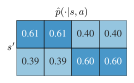

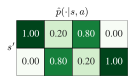

In [ ]:
df_Phat_orig = pd.DataFrame(avg_P_orig.reshape((4,2)), index=sa, columns=s_)

fig, ax = plt.subplots(figsize=(2, 1))
sns.heatmap(
    df_Phat_orig.T, ax=ax, annot=True, square=True,
    cmap='Blues', fmt='.2f', vmin=0, vmax=1, cbar=False,
    linewidths=0.5, linecolor='black', xticklabels=False, yticklabels=False,
)
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
plt.tick_params(axis='x', which='both', length=0)
plt.tick_params(axis='y', which='both', length=0, rotation=0)
plt.xlabel(r'$\hat{p}(\cdot | s,a)$')
plt.ylabel("$s'$", rotation=0)
ax.xaxis.set_label_coords(0.5, 1.24)
ax.yaxis.set_label_coords(-0.05, 0.425)
plt.savefig('synthetic_p_hat_orig.pdf', bbox_inches='tight')
plt.show()

df_Phat_shifted = pd.DataFrame(avg_P_shifted.reshape((4,2)), index=sa, columns=s_)

fig, ax = plt.subplots(figsize=(2, 3.5))
sns.heatmap(
    df_Phat_shifted.T, ax=ax, annot=True, square=True,
    cmap='Greens', fmt='.2f', vmin=0, vmax=1, cbar=False,
    linewidths=0.5, linecolor='black', xticklabels=False, yticklabels=False,
)
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
plt.tick_params(axis='x', which='both', length=0)
plt.tick_params(axis='y', which='both', length=0, rotation=0)
plt.xlabel(r'$\hat{p}(\cdot | s,a)$')
plt.ylabel("$s'$", rotation=0)
ax.xaxis.set_label_coords(0.5, 1.24)
ax.yaxis.set_label_coords(-0.05, 0.425)
plt.savefig('synthetic_p_hat_shifted.pdf', bbox_inches='tight')
plt.show()

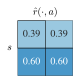

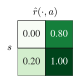

In [ ]:
df_Rhat_orig = pd.DataFrame(avg_R_orig, index=[0,1], columns=[0,1])

fig, ax = plt.subplots(figsize=(1, 1))
sns.heatmap(
    df_Rhat_orig, ax=ax, annot=True, square=True,
    cmap='Blues', fmt='.2f', vmin=0, vmax=1, cbar=False,
    linewidths=0.5, linecolor='black', xticklabels=False, yticklabels=False,
)
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
plt.tick_params(axis='x', which='both', length=0)
plt.tick_params(axis='y', which='both', length=0, rotation=0)
plt.xlabel(r'$\hat{r}(\cdot,a)$')
plt.ylabel("$s$", rotation=0)
ax.xaxis.set_label_coords(0.5, 1.24)
ax.yaxis.set_label_coords(-0.15, 0.425)
plt.savefig('synthetic_r_hat_orig.pdf', bbox_inches='tight')
plt.show()

df_Rhat_shifted = pd.DataFrame(avg_R_shifted, index=[0,1], columns=[0,1])

fig, ax = plt.subplots(figsize=(1, 1))
sns.heatmap(
    df_Rhat_shifted, ax=ax, annot=True, square=True,
    cmap='Greens', fmt='.2f', vmin=0, vmax=1, cbar=False,
    linewidths=0.5, linecolor='black', xticklabels=False, yticklabels=False,
)
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
plt.tick_params(axis='x', which='both', length=0)
plt.tick_params(axis='y', which='both', length=0, rotation=0)
plt.xlabel(r'$\hat{r}(\cdot,a)$')
plt.ylabel("$s$", rotation=0)
ax.xaxis.set_label_coords(0.5, 1.24)
ax.yaxis.set_label_coords(-0.15, 0.425)
plt.savefig('synthetic_r_hat_shifted.pdf', bbox_inches='tight')
plt.show()

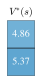

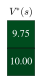

In [ ]:
df_Vhat_orig = pd.DataFrame(avg_V_orig, index=[0,1])

fig, ax = plt.subplots(figsize=(1, 1))
sns.heatmap(
    df_Vhat_orig, ax=ax, annot=True, square=True,
    cmap='Blues', fmt='.2f', vmin=0, vmax=10, cbar=False,
    linewidths=0.5, linecolor='black', xticklabels=False, yticklabels=False,
)
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
plt.tick_params(axis='x', which='both', length=0)
plt.tick_params(axis='y', which='both', length=0, rotation=0)
plt.xlabel('$V^{*}(s)$')
ax.xaxis.set_label_coords(0.5, 1.24)
plt.savefig('synthetic_Vstar_orig.pdf', bbox_inches='tight')
plt.show()

df_Vhat_shifted = pd.DataFrame(avg_V_shifted, index=[0,1])

fig, ax = plt.subplots(figsize=(1, 1))
sns.heatmap(
    df_Vhat_shifted, ax=ax, annot=True, square=True,
    cmap='Greens', fmt='.2f', vmin=0, vmax=10, cbar=False,
    linewidths=0.5, linecolor='black', xticklabels=False, yticklabels=False,
)
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
plt.tick_params(axis='x', which='both', length=0)
plt.tick_params(axis='y', which='both', length=0, rotation=0)
plt.xlabel('$V^{*}(s)$')
ax.xaxis.set_label_coords(0.5, 1.24)
plt.savefig('synthetic_Vstar_shifted.pdf', bbox_inches='tight')
plt.show()

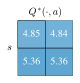

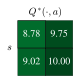

In [ ]:
df_Qhat_orig = pd.DataFrame(avg_Q_orig, index=[0,1], columns=[0,1])

fig, ax = plt.subplots(figsize=(1, 1))
sns.heatmap(
    df_Qhat_orig, ax=ax, annot=True, square=True,
    cmap='Blues', fmt='.2f', vmin=0, vmax=10, cbar=False,
    linewidths=0.5, linecolor='black', xticklabels=False, yticklabels=False,
)
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
plt.tick_params(axis='x', which='both', length=0)
plt.tick_params(axis='y', which='both', length=0, rotation=0)
plt.xlabel(r'$Q^{*}(\cdot, a)$')
plt.ylabel("$s$", rotation=0)
ax.xaxis.set_label_coords(0.5, 1.24)
ax.yaxis.set_label_coords(-0.15, 0.425)
plt.savefig('synthetic_Qstar_orig.pdf', bbox_inches='tight')
plt.show()

df_Qhat_shifted = pd.DataFrame(avg_Q_shifted, index=[0,1], columns=[0,1])

fig, ax = plt.subplots(figsize=(1, 1))
sns.heatmap(
    df_Qhat_shifted, ax=ax, annot=True, square=True,
    cmap='Greens', fmt='.2f', vmin=0, vmax=10, cbar=False,
    linewidths=0.5, linecolor='black', xticklabels=False, yticklabels=False,
)
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
plt.tick_params(axis='x', which='both', length=0)
plt.tick_params(axis='y', which='both', length=0, rotation=0)
plt.xlabel(r'$Q^{*}(\cdot, a)$')
plt.ylabel("$s$", rotation=0)
ax.xaxis.set_label_coords(0.5, 1.24)
ax.yaxis.set_label_coords(-0.15, 0.425)
plt.savefig('synthetic_Qstar_shifted.pdf', bbox_inches='tight')
plt.show()

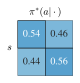

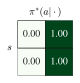

In [ ]:
df_πhat_orig = pd.DataFrame(avg_π_orig, index=[0,1], columns=[0,1])

fig, ax = plt.subplots(figsize=(1, 1))
sns.heatmap(
    df_πhat_orig, ax=ax, annot=True, square=True,
    cmap='Blues', fmt='.2f', vmin=0, vmax=1, cbar=False,
    linewidths=0.5, linecolor='black', xticklabels=False, yticklabels=False,
)
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
plt.tick_params(axis='x', which='both', length=0)
plt.tick_params(axis='y', which='both', length=0, rotation=0)
plt.xlabel(r'$\pi^{*}(a | \cdot)$')
plt.ylabel("$s$", rotation=0)
ax.xaxis.set_label_coords(0.5, 1.24)
ax.yaxis.set_label_coords(-0.15, 0.425)
plt.savefig('synthetic_pistar_orig.pdf', bbox_inches='tight')
plt.show()

df_πhat_shifted = pd.DataFrame(avg_π_shifted, index=[0,1], columns=[0,1])

fig, ax = plt.subplots(figsize=(1, 1))
sns.heatmap(
    df_πhat_shifted, ax=ax, annot=True, square=True,
    cmap='Greens', fmt='.2f', vmin=0, vmax=1, cbar=False,
    linewidths=0.5, linecolor='black', xticklabels=False, yticklabels=False,
)
ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
plt.tick_params(axis='x', which='both', length=0)
plt.tick_params(axis='y', which='both', length=0, rotation=0)
plt.xlabel(r'$\pi^{*}(a | \cdot)$')
plt.ylabel("$s$", rotation=0)
ax.xaxis.set_label_coords(0.5, 1.24)
ax.yaxis.set_label_coords(-0.15, 0.425)
plt.savefig('synthetic_pistar_shifted.pdf', bbox_inches='tight')
plt.show()

### Offline evaluation

In [ ]:
all_test_results = []
for run in tqdm(range(100)):
    π_b = generate_random_behavior_policy(2, 2, seed=run)
    test_episode_data = generate_dataset(env, π_b, num_episodes=NUM_EPISODES, seed=200+run, show_progress=False)
    test_results = run_experiment_evaluation(all_results[run], test_episode_data, π_b)
    all_test_results.append(test_results)

100%|██████████| 100/100 [01:06<00:00,  1.50it/s]


In [ ]:
df_output = []
for test_results in all_test_results:
    df_output.append([
        test_results['orig']['V_πb'].mean(), test_results['orig']['V'].mean(),
        test_results['shifted']['V_πb'].mean(), test_results['shifted']['V'].mean(),
    ])

df_output = pd.DataFrame(df_output, columns=['V_πb_orig', 'V_orig', 'V_πb_shifted', 'V_shifted'])

In [ ]:
df_output['correct_π_orig'] = [np.all(results['orig']['π'] == results['shifted']['π']) for results in all_results]

In [ ]:
df_output

,V_πb_orig,V_orig,V_πb_shifted,V_shifted,correct_π_orig
0,2.915770,2.985992,2.969290,9.884364,False
1,8.066508,7.918976,8.166821,9.893174,True
2,3.719536,3.692448,3.726903,9.871542,True
3,5.448530,5.518141,5.553188,9.875639,True
4,2.689561,2.727856,2.747859,9.876267,False
...,...,...,...,...,...
95,6.320724,6.293187,6.293208,9.881328,False
96,4.887686,4.669895,4.897354,9.869810,True
97,5.196061,5.221991,5.249883,9.875388,False
98,7.101402,7.411394,6.963842,9.892708,False


In [ ]:
(~df_output['correct_π_orig']).mean()

np.float64(0.72)

In [ ]:
(df_output['V_πb_orig'] < df_output['V_orig']).mean()

np.float64(0.45)

In [ ]:
((df_output['V_πb_orig'] < df_output['V_orig']) & (~df_output['correct_π_orig'])).mean()

np.float64(0.33)

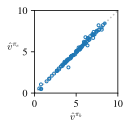

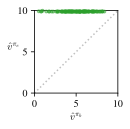

In [ ]:
Vmin, Vmax = 0, 10
fig, ax = plt.subplots(figsize=(1.5, 1.5))
plt.plot('V_πb_orig', 'V_orig', 'o', data=df_output[df_output['correct_π_orig']], markersize=3, alpha=0.75, color='tab:blue', zorder=10, clip_on=False)
plt.plot('V_πb_orig', 'V_orig', 'o', data=df_output[~df_output['correct_π_orig']], markersize=3, mfc='none', alpha=1, color='tab:blue', zorder=10, clip_on=False)
plt.xlabel(r'$\hat{v}^{\pi_b}$')
plt.ylabel(r'$\hat{v}^{\pi_e}$', rotation=0)
plt.xlim(Vmin, Vmax)
plt.ylim(Vmin, Vmax)
plt.xticks(np.arange(Vmin, Vmax+0.01, 5))
plt.yticks(np.arange(Vmin, Vmax+0.01, 5))
plt.plot([Vmin, Vmax], [Vmin, Vmax], ':', color='gray', alpha=0.5)
plt.savefig('toy_problem_stochastic_OPE_orig.pdf', bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(1.5, 1.5))
plt.plot('V_πb_shifted', 'V_shifted', 'o', data=df_output, markersize=3, alpha=0.5, color='tab:green', zorder=10, clip_on=False)
plt.xlabel(r'$\hat{v}^{\pi_b}$')
plt.ylabel(r'$\hat{v}^{\pi_e}$', rotation=0)
plt.xlim(Vmin, Vmax)
plt.ylim(Vmin, Vmax)
plt.xticks(np.arange(Vmin, Vmax+0.01, 5))
plt.yticks(np.arange(Vmin, Vmax+0.01, 5))
plt.plot([Vmin, Vmax], [Vmin, Vmax], ':', color='gray', alpha=0.5)
plt.savefig('toy_problem_stochastic_OPE_shifted.pdf', bbox_inches='tight')
plt.show()

### Online evaluation

In [ ]:
P = np.array([
    [[1., 0.], [0.2, 0.8]],
    [[0.8, 0.2], [0., 1.]],
])
R = np.array([
    [0., 1.],
    [0., 1.],
])

In [ ]:
V_true_orig, _ = policy_evaluation_iterative(P, R, avg_π_orig)
V_true_shifted, _ = policy_evaluation_iterative(P, R, avg_π_shifted)

In [ ]:
print(V_true_orig.mean(), V_true_shifted.mean())

5.109625667624283 9.999999999142268


In [ ]:
online_rollout_orig = generate_dataset(env, avg_π_orig, seed=100, num_episodes=NUM_EPISODES, show_progress=False)
online_rollout_shifted = generate_dataset(env, avg_π_shifted, seed=100, num_episodes=NUM_EPISODES, show_progress=False)
returns_orig = np.array([calculate_discounted_return(ep) for ep in online_rollout_orig])
returns_shifted = np.array([calculate_discounted_return(ep) for ep in online_rollout_shifted])

In [ ]:
print(returns_orig.mean(), returns_shifted.mean())

5.073544335571479 9.886344386011125


### Visualize online rollouts

In [ ]:
MAX_EPISODES_STEPS = 20
NUM_EPISODES = 500

In [ ]:
env = TimeLimit(
    ToyEnvNew(slip_prob=0.2, internal_dt=0.05),
    max_episode_steps=MAX_EPISODES_STEPS,
)

ToyEnvNew initialized. step_dt=1.0, internal_dt=0.05, slip_prob=0.2


In [ ]:
online_rollout_orig = generate_dataset(env, avg_π_orig, seed=100, num_episodes=NUM_EPISODES, show_progress=False)
online_rollout_shifted = generate_dataset(env, avg_π_shifted, seed=100, num_episodes=NUM_EPISODES, show_progress=False)

In [ ]:
orig_trajectories = []
for ep in online_rollout_orig:
    orig_internal_traj = stitch_internal_traj([info for a_curr, s, a, r, s_next, info in ep], 1.0)
    orig_trajectories.append({
        't_traj': orig_internal_traj[0],
        'x_traj': orig_internal_traj[1],
        'u_traj': orig_internal_traj[2],
        't_traj_': orig_internal_traj[3],
        'u_traj_': orig_internal_traj[4],
    })

shifted_trajectories = []
for ep in online_rollout_shifted:
    shifted_internal_traj = stitch_internal_traj([info for a_curr, s, a, r, s_next, info in ep], 1.0)
    shifted_trajectories.append({
        't_traj': shifted_internal_traj[0],
        'x_traj': shifted_internal_traj[1],
        'u_traj': shifted_internal_traj[2],
        't_traj_': shifted_internal_traj[3],
        'u_traj_': shifted_internal_traj[4],
    })

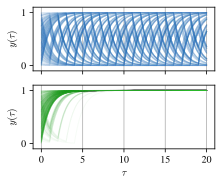

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(3,2.5), sharex=True)
c1 = 'tab:blue'
c2 = 'tab:green'
axes[0].grid(axis='x')
axes[1].grid(axis='x')

for i in range(NUM_EPISODES):
    t_traj = orig_trajectories[i]['t_traj']
    x_traj = orig_trajectories[i]['x_traj']
    u_traj = orig_trajectories[i]['u_traj']
    t_traj_ = orig_trajectories[i]['t_traj_']
    u_traj_ = orig_trajectories[i]['u_traj_']
    axes[0].plot(t_traj, x_traj, lw=1, color=c1, alpha=0.2*100/NUM_EPISODES)

for i in range(NUM_EPISODES):
    t_traj = shifted_trajectories[i]['t_traj']
    x_traj = shifted_trajectories[i]['x_traj']
    u_traj = shifted_trajectories[i]['u_traj']
    t_traj_ = shifted_trajectories[i]['t_traj_']
    u_traj_ = shifted_trajectories[i]['u_traj_']
    axes[1].plot(t_traj, x_traj, lw=1, color=c2, alpha=0.2*100/NUM_EPISODES)

axes[0].set_ylim(-0.1, 1.1)
axes[1].set_ylim(-0.1, 1.1)
axes[0].set_yticks([0, 1.0])
axes[1].set_yticks([0, 1.0])
# axes[0].set_title('"shifted"')
plt.tight_layout()
plt.xlabel('$\\tau$')
axes[0].set_ylabel('$y(\\tau)$')
axes[1].set_ylabel('$y(\\tau)$')
plt.savefig('toy_problem_online_rollout.pdf', bbox_inches='tight')
plt.show()

## Experiments with near-optimal behavior

In [38]:
def generate_near_optimal_behavior_policy(n_states=2, n_actions=2, seed=None):
    policy = np.zeros((n_states, n_actions))
    policy[:,0] = np.random.default_rng(seed=seed).random((1, n_actions))*0.05
    policy[:,1] = 1 - policy[:,0]
    return policy

### Learning

In [39]:
MAX_EPISODES_STEPS = 100
NUM_EPISODES = 100

In [40]:
env = TimeLimit(
    ToyEnvNew(slip_prob=0.1),
    max_episode_steps=MAX_EPISODES_STEPS,
)

ToyEnvNew initialized. step_dt=1.0, internal_dt=None, slip_prob=0.1


In [41]:
all_results = []
for run in tqdm(range(100)):
    π_b = generate_near_optimal_behavior_policy(2, 2, seed=run)
    episode_data = generate_dataset(env, π_b, num_episodes=NUM_EPISODES, seed=100+run, show_progress=False)
    results = run_experiment(episode_data)
    all_results.append(results)

  3%|▎         | 3/100 [00:02<01:35,  1.02it/s]/usr/local/lib/python3.12/dist-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/tmp/ipython-input-1230074664.py:22: RuntimeWarning: invalid value encountered in divide
  P[s, a, :] /= np.sum(P[s, a, :])
100%|██████████| 100/100 [01:12<00:00,  1.38it/s]


In [42]:
# average P
avg_P_orig = np.nanmean([results['orig']['P'] for results in all_results], axis=0)
avg_P_shifted = np.nanmean([results['shifted']['P'] for results in all_results], axis=0)

In [43]:
avg_P_orig, avg_P_shifted

(array([[[0.12450969, 0.87549031],
         [0.1188107 , 0.8811893 ]],
 
        [[0.02524042, 0.97475958],
         [0.02400916, 0.97599084]]]),
 array([[[1.        , 0.        ],
         [0.09945518, 0.90054482]],
 
        [[0.90102527, 0.09897473],
         [0.        , 1.        ]]]))

In [44]:
# average R
avg_R_orig = np.nanmean([results['orig']['R'] for results in all_results], axis=0)
avg_R_shifted = np.nanmean([results['shifted']['R'] for results in all_results], axis=0)

In [45]:
avg_R_orig, avg_R_shifted

(array([[0.87549031, 0.8811893 ],
        [0.97475958, 0.97599084]]),
 array([[0.        , 0.90054482],
        [0.09897473, 1.        ]]))

In [46]:
# average V
avg_V_orig = np.nanmean([results['orig']['V'] for results in all_results], axis=0)
avg_V_shifted = np.nanmean([results['shifted']['V'] for results in all_results], axis=0)

# average Q
avg_Q_orig = np.nanmean([results['orig']['Q'] for results in all_results], axis=0)
avg_Q_shifted = np.nanmean([results['shifted']['Q'] for results in all_results], axis=0)

In [47]:
# average π
avg_π_orig = np.nanmean([results['orig']['π'] for results in all_results], axis=0)
avg_π_shifted = np.nanmean([results['shifted']['π'] for results in all_results], axis=0)

In [48]:
avg_π_orig, avg_π_shifted

(array([[0.37, 0.63],
        [0.61, 0.39]]),
 array([[0., 1.],
        [0., 1.]]))

### Offline evaluation

In [ ]:
all_test_results = []
for run in tqdm(range(100)):
    π_b = generate_near_optimal_behavior_policy(2, 2, seed=run)
    test_episode_data = generate_dataset(env, π_b, num_episodes=NUM_EPISODES, seed=200+run, show_progress=False)
    test_results = run_experiment_evaluation(all_results[run], test_episode_data, π_b)
    all_test_results.append(test_results)

  3%|▎         | 3/100 [00:01<01:01,  1.58it/s]/tmp/ipython-input-1754135439.py:22: RuntimeWarning: invalid value encountered in divide
  P[s, a, :] /= np.sum(P[s, a, :])
100%|██████████| 100/100 [01:08<00:00,  1.47it/s]


In [ ]:
df_output = []
for test_results in all_test_results:
    df_output.append([
        test_results['orig']['V_πb'].mean(), test_results['orig']['V'].mean(),
        test_results['shifted']['V_πb'].mean(), test_results['shifted']['V'].mean(),
    ])

df_output = pd.DataFrame(df_output, columns=['V_πb_orig', 'V_orig', 'V_πb_shifted', 'V_shifted'])

In [ ]:
df_output['correct_π_orig'] = [np.all(results['orig']['π'] == results['shifted']['π']) for results in all_results]

In [ ]:
df_output

,V_πb_orig,V_orig,V_πb_shifted,V_shifted,correct_π_orig
0,9.794140,9.911374,9.783689,9.934211,False
1,9.528414,9.509390,9.493912,9.943533,True
2,9.853919,9.337900,9.805312,9.947230,False
3,9.792537,9.896907,9.782713,9.919679,False
4,9.603458,9.863813,9.665728,9.942071,False
...,...,...,...,...,...
95,9.593774,9.406332,9.537693,9.949495,False
96,9.613794,9.611350,9.574101,9.932546,True
97,9.721300,9.385965,9.720639,9.946577,False
98,9.606288,9.586091,9.555216,9.962244,False


In [ ]:
(~df_output['correct_π_orig']).mean()

np.float64(0.75)

In [ ]:
(df_output['V_πb_orig'] < df_output['V_orig']).mean()

np.float64(0.49)

In [ ]:
((df_output['V_πb_orig'] < df_output['V_orig']) & (~df_output['correct_π_orig'])).mean()

np.float64(0.42)

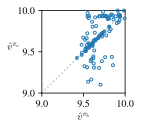

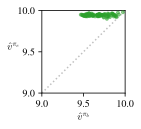

In [ ]:
Vmin, Vmax = 9, 10
fig, ax = plt.subplots(figsize=(1.5, 1.5))
plt.plot('V_πb_orig', 'V_orig', 'o', data=df_output[df_output['correct_π_orig']], markersize=3, alpha=0.75, color='tab:blue', zorder=10, clip_on=False)
plt.plot('V_πb_orig', 'V_orig', 'o', data=df_output[~df_output['correct_π_orig']], markersize=3, mfc='none', alpha=1, color='tab:blue', zorder=10, clip_on=False)
plt.xlabel(r'$\hat{v}^{\pi_b}$')
plt.ylabel(r'$\hat{v}^{\pi_e}$', rotation=0)
plt.xlim(Vmin, Vmax)
plt.ylim(Vmin, Vmax)
plt.xticks(np.arange(Vmin, Vmax+0.01, 0.5))
plt.yticks(np.arange(Vmin, Vmax+0.01, 0.5))
plt.plot([Vmin, Vmax], [Vmin, Vmax], ':', color='gray', alpha=0.5)
plt.savefig('toy_problem_near_deterministic_OPE_orig.pdf', bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(1.5, 1.5))
plt.plot('V_πb_shifted', 'V_shifted', 'o', data=df_output, markersize=3, alpha=0.5, color='tab:green', zorder=10, clip_on=False)
plt.xlabel(r'$\hat{v}^{\pi_b}$')
plt.ylabel(r'$\hat{v}^{\pi_e}$', rotation=0)
plt.xlim(Vmin, Vmax)
plt.ylim(Vmin, Vmax)
plt.xticks(np.arange(Vmin, Vmax+0.01, 0.5))
plt.yticks(np.arange(Vmin, Vmax+0.01, 0.5))
plt.plot([Vmin, Vmax], [Vmin, Vmax], ':', color='gray', alpha=0.5)
plt.savefig('toy_problem_near_deterministic_OPE_shifted.pdf', bbox_inches='tight')
plt.show()

### Online evaluation

In [ ]:
P = np.array([
    [[1., 0.], [0.2, 0.8]],
    [[0.8, 0.2], [0., 1.]],
])
R = np.array([
    [0., 1.],
    [0., 1.],
])

In [ ]:
V_true_orig, _ = policy_evaluation_iterative(P, R, avg_π_orig)
V_true_shifted, _ = policy_evaluation_iterative(P, R, avg_π_shifted)

In [ ]:
print(V_true_orig.mean(), V_true_shifted.mean())

5.082594680888299 9.999999999142268


In [ ]:
online_rollout_orig = generate_dataset(env, avg_π_orig, seed=100, num_episodes=NUM_EPISODES, show_progress=False)
online_rollout_shifted = generate_dataset(env, avg_π_shifted, seed=100, num_episodes=NUM_EPISODES, show_progress=False)
returns_orig = np.array([calculate_discounted_return(ep) for ep in online_rollout_orig])
returns_shifted = np.array([calculate_discounted_return(ep) for ep in online_rollout_shifted])

In [ ]:
print(returns_orig.mean(), returns_shifted.mean())

5.084023840450242 9.959734386011124


### Visualize online rollouts

In [49]:
MAX_EPISODES_STEPS = 20
NUM_EPISODES = 500

In [50]:
env = TimeLimit(
    ToyEnvNew(slip_prob=0.2, internal_dt=0.05),
    max_episode_steps=MAX_EPISODES_STEPS,
)

ToyEnvNew initialized. step_dt=1.0, internal_dt=0.05, slip_prob=0.2


In [55]:
online_rollout_orig = generate_dataset(env, avg_π_orig, seed=300, num_episodes=NUM_EPISODES, show_progress=False)
online_rollout_shifted = generate_dataset(env, avg_π_shifted, seed=300, num_episodes=NUM_EPISODES, show_progress=False)

In [56]:
orig_trajectories = []
for ep in online_rollout_orig:
    orig_internal_traj = stitch_internal_traj([info for a_curr, s, a, r, s_next, info in ep], 1.0)
    orig_trajectories.append({
        't_traj': orig_internal_traj[0],
        'x_traj': orig_internal_traj[1],
        'u_traj': orig_internal_traj[2],
        't_traj_': orig_internal_traj[3],
        'u_traj_': orig_internal_traj[4],
    })

shifted_trajectories = []
for ep in online_rollout_shifted:
    shifted_internal_traj = stitch_internal_traj([info for a_curr, s, a, r, s_next, info in ep], 1.0)
    shifted_trajectories.append({
        't_traj': shifted_internal_traj[0],
        'x_traj': shifted_internal_traj[1],
        'u_traj': shifted_internal_traj[2],
        't_traj_': shifted_internal_traj[3],
        'u_traj_': shifted_internal_traj[4],
    })

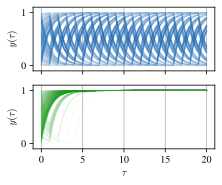

In [57]:
fig, axes = plt.subplots(2, 1, figsize=(3,2.5), sharex=True)
c1 = 'tab:blue'
c2 = 'tab:green'
axes[0].grid(axis='x')
axes[1].grid(axis='x')

for i in range(NUM_EPISODES):
    t_traj = orig_trajectories[i]['t_traj']
    x_traj = orig_trajectories[i]['x_traj']
    u_traj = orig_trajectories[i]['u_traj']
    t_traj_ = orig_trajectories[i]['t_traj_']
    u_traj_ = orig_trajectories[i]['u_traj_']
    axes[0].plot(t_traj, x_traj, lw=1, color=c1, alpha=0.2*100/NUM_EPISODES)

for i in range(NUM_EPISODES):
    t_traj = shifted_trajectories[i]['t_traj']
    x_traj = shifted_trajectories[i]['x_traj']
    u_traj = shifted_trajectories[i]['u_traj']
    t_traj_ = shifted_trajectories[i]['t_traj_']
    u_traj_ = shifted_trajectories[i]['u_traj_']
    axes[1].plot(t_traj, x_traj, lw=1, color=c2, alpha=0.2*100/NUM_EPISODES)

axes[0].set_ylim(-0.1, 1.1)
axes[1].set_ylim(-0.1, 1.1)
axes[0].set_yticks([0, 1.0])
axes[1].set_yticks([0, 1.0])
# axes[0].set_title('"shifted"')
plt.tight_layout()
plt.xlabel('$\\tau$')
axes[0].set_ylabel('$y(\\tau)$')
axes[1].set_ylabel('$y(\\tau)$')
plt.savefig('toy_problem_near_deterministic_online_rollout.pdf', bbox_inches='tight')
plt.show()

## Download figures

In [ ]:
!zip -r fig.zip *.pdf

  adding: synthetic_p_hat_orig.pdf (deflated 46%)
  adding: synthetic_p_hat_shifted.pdf (deflated 47%)
  adding: synthetic_pistar_orig.pdf (deflated 48%)
  adding: synthetic_pistar_shifted.pdf (deflated 50%)
  adding: synthetic_Qstar_orig.pdf (deflated 46%)
  adding: synthetic_Qstar_shifted.pdf (deflated 45%)
  adding: synthetic_r_hat_orig.pdf (deflated 48%)
  adding: synthetic_r_hat_shifted.pdf (deflated 49%)
  adding: synthetic_Vstar_orig.pdf (deflated 50%)
  adding: synthetic_Vstar_shifted.pdf (deflated 51%)
  adding: toy_problem_near_deterministic_online_rollout.pdf (deflated 1%)
  adding: toy_problem_near_deterministic_OPE_orig.pdf (deflated 40%)
  adding: toy_problem_near_deterministic_OPE_shifted.pdf (deflated 40%)
  adding: toy_problem_stochastic_OPE_orig.pdf (deflated 41%)
  adding: toy_problem_stochastic_OPE_shifted.pdf (deflated 41%)
